# Solution 4 (comparison only): seeded graph matching (SGM / FAQ)

> **Throwaway experiment.** The main method is greedy percolation (`solution.ipynb`). This notebook only tests another alternative and compares it with percolation, solution 2 and solution 3. All outputs are in `solution4_out/`; delete that folder and this notebook to remove everything. Main deliverables (`config.json`, `results/`, `predictions/`, `report.md`) and the `solution2_out/`, `solution3_out/` folders are only **read**.

**Idea.** The earlier methods score a pair by counting matched *neighbours*. Seeded graph matching instead searches for the whole mapping that makes the two edge sets agree as much as possible:

`maximise  f(P) = trace(A P B P^T)`  over permutation matrices `P` that contain the seed pairs.

Writing `P` as a fixed seed block plus an unknown block `X` over the unseeded nodes, the problem is relaxed to doubly-stochastic `X` and solved with **Frank-Wolfe**: at each iteration compute the gradient `G = A P B`, solve one `linear_sum_assignment` on the unseeded block of `G` to get a direction, choose the exact line-search step (the objective is quadratic along the segment), and move. At the end `X` is projected back to a permutation with one more assignment. The result is non-convex, so the **initialisation** matters: the barycentre (uniform `X`), the permutation implied by the seed votes, or a 50/50 mix.

Unlike percolation it uses every edge from the first iteration, not only edges next to matched pairs. We track the final edge-agreement of each matched pair (`score`, the number of agreeing neighbour pairs under the final mapping) as a confidence value, and we can optionally reject pairs with `score < tau`.

## 1. Setup and data loading (same loader and metrics as the main notebook)

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_based')
MAIN = Path('results')            # main (percolation) results: read only
SOL2 = Path('solution2_out')      # solution 2 results: read only
SOL3 = Path('solution3_out')      # solution 3 results: read only
OUT = Path('solution4_out')       # everything this notebook writes
OUT.mkdir(exist_ok=True)
(OUT / 'figs').mkdir(exist_ok=True)

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency without self-loops or duplicate edges."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def load_instance(split, name, seed_kind="random", seed_pct=5):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    seeds = pd.read_csv(d / f"seeds_{seed_kind}_{seed_pct:02d}.csv")
    seeds = dict(zip(seeds.node_a, seeds.node_b))
    gt = d / "ground_truth.csv"
    truth = None
    if gt.exists():
        t = pd.read_csv(gt)
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, seeds, truth, meta


In [3]:
def evaluate(pred, truth, seeds, n):
    """Precision / recall / F1 / coverage, overall and on unseeded nodes only."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    un_pred = {a: b for a, b in pred.items() if a not in seeds}
    un_truth_n = n - len(seeds)
    un_correct = sum(truth.get(a) == b for a, b in un_pred.items())
    un_p = un_correct / len(un_pred) if un_pred else 0.0
    un_r = un_correct / un_truth_n if un_truth_n else 0.0
    un_f1 = 2 * un_p * un_r / (un_p + un_r) if un_p + un_r else 0.0
    return dict(
        precision=p, recall=r, f1=f1, coverage=len(pred) / n,
        unseeded_precision=un_p, unseeded_recall=un_r, unseeded_f1=un_f1,
        unseeded_coverage=len(un_pred) / un_truth_n if un_truth_n else 0.0,
    )


def degree_rank_baseline(A, B, seeds):
    """Pair unseeded nodes by degree rank (a deliberately weak floor)."""
    da = np.asarray(A.sum(1)).ravel()
    db = np.asarray(B.sum(1)).ravel()
    ua = [u for u in np.argsort(-da, kind="stable") if u not in seeds]
    used_b = set(seeds.values())
    ub = [v for v in np.argsort(-db, kind="stable") if v not in used_b]
    pred = dict(seeds)
    pred.update(zip(ua, ub))
    return pred


## 2. The method
`match_sgm` works on the unseeded block. `gradient(P~)` computes `A P~ B` with two sparse-times-dense products (`P~` is the seed permutation plus the current block `X`). Every Frank-Wolfe iteration: gradient, assignment direction, exact line search `alpha = -c / (2 d)` clipped to [0, 1] (with `c` the directional derivative and `d` the curvature along the segment), update. It stops when the Frank-Wolfe gap is below `tol` or the step is zero. The per-iteration objective is recorded (it must be non-decreasing).

In [4]:
def match_sgm(A, B, seeds, init="mix", max_iter=30, tol=1.0, tau=None):
    """Seeded graph matching: Frank-Wolfe on the unseeded block, exact line search, final LAP projection."""
    n = A.shape[0]
    sa = np.array(list(seeds.keys())); sb = np.array(list(seeds.values()))
    ua = np.setdiff1d(np.arange(n), sa); ub = np.setdiff1d(np.arange(n), sb)
    m = len(ua); assert m == len(ub)
    S0 = np.zeros((n, n), np.float32); S0[sa, sb] = 1
    dA = np.asarray(A.sum(1)).ravel(); dB = np.asarray(B.sum(1)).ravel()
    tb = (-np.abs(dA[ua][:, None] - dB[ub][None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3).astype(np.float32)

    def gradient(Pt):                      # A @ Pt @ B  (A, B symmetric)
        return np.asarray(A @ (B @ Pt.T).T, dtype=np.float32)

    def embed(X):
        Pt = S0.copy(); Pt[np.ix_(ua, ub)] = X
        return Pt

    def lap_max(G):
        r, c = linear_sum_assignment(-G)
        Q = np.zeros(G.shape, np.float32); Q[r, c] = 1
        return Q

    bary = np.full((m, m), 1.0 / m, np.float32)
    if init == "bary":
        X = bary
    else:
        Q0 = lap_max(gradient(S0)[np.ix_(ua, ub)] + tb)      # permutation implied by the seed votes
        X = Q0 if init == "vote" else 0.5 * bary + 0.5 * Q0
    objs = []
    for it in range(max_iter):
        Pt = embed(X); G = gradient(Pt); Gb = G[np.ix_(ua, ub)]
        objs.append(float((G * Pt).sum()))
        D = lap_max(Gb) - X
        gap = float((Gb * D).sum())
        if gap <= tol:
            break
        Df = np.zeros((n, n), np.float32); Df[np.ix_(ua, ub)] = D
        c = 2 * gap
        d = float((gradient(Df)[np.ix_(ua, ub)] * D).sum())
        alpha = min(1.0, max(0.0, -c / (2 * d))) if d < 0 else (1.0 if c + d > 0 else 0.0)
        if alpha <= 0:
            break
        X = X + alpha * D
    r, c_ = linear_sum_assignment(-X)                          # project to a permutation
    Pt = embed(np.zeros((m, m), np.float32)); Pt[ua[r], ub[c_]] = 1
    G = gradient(Pt)
    objs.append(float((G * Pt).sum()))
    score = G[ua[r], ub[c_]]                                   # agreeing neighbour pairs under the final mapping
    pred = dict(seeds)
    log = []
    for u, v, sc in zip(ua[r], ub[c_], score):
        if tau is None or sc >= tau:
            pred[int(u)] = int(v); log.append((int(u), int(v), float(sc)))
    info = pd.DataFrame(log, columns=["node_a", "node_b", "score"])
    info.attrs["objs"] = objs; info.attrs["iters"] = len(objs) - 1
    return pred, info


def edge_agreement(A, B, mapping):
    """f(P) = trace(A P B P^T) = number of (ordered) edge pairs that agree under the mapping."""
    n = A.shape[0]
    Pt = np.zeros((n, n), np.float32); Pt[list(mapping.keys()), list(mapping.values())] = 1
    return float((np.asarray(A @ (B @ Pt.T).T, dtype=np.float32) * Pt).sum())

In [5]:
# Sanity checks on one instance (5% random seeds)
A, B, seeds, truth, meta = load_instance('val', 'erdos_renyi_hard_00', 'random', 5)
n = A.shape[0]
print({k: round(v, 3) for k, v in evaluate(dict(truth), truth, seeds, n).items()})   # perfect -> 1.0
print(round(evaluate(dict(seeds), truth, seeds, n)['unseeded_recall'], 3))            # seeds only -> 0
t = time.perf_counter(); pred, info = match_sgm(A, B, seeds); dt = time.perf_counter() - t
assert len(set(pred)) == len(pred) and len(set(pred.values())) == len(pred), "duplicate ids"
objs = np.array(info.attrs["objs"][:-1])
assert (np.diff(objs) >= -1e-3 * np.abs(objs[:-1])).all(), "Frank-Wolfe objective must not decrease"
print(f"Frank-Wolfe objective non-decreasing over {len(objs)} iterations: OK ({dt:.1f}s)")
print("edge agreement  found:", edge_agreement(A, B, pred), "| ground truth:", edge_agreement(A, B, truth))
demo = pd.DataFrame({
    'seeds only': evaluate(dict(seeds), truth, seeds, n),
    'degree rank': evaluate(degree_rank_baseline(A, B, seeds), truth, seeds, n),
    'SGM (mix init)': evaluate(pred, truth, seeds, n),
}).T[['precision', 'recall', 'f1', 'coverage', 'unseeded_precision', 'unseeded_recall']]
display(demo.round(3))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'coverage': 1.0, 'unseeded_precision': 1.0, 'unseeded_recall': 1.0, 'unseeded_f1': 1.0, 'unseeded_coverage': 1.0}
0.0
Frank-Wolfe objective non-decreasing over 2 iterations: OK (0.1s)
edge agreement  found: 43788.0 | ground truth: 43788.0


,precision,recall,f1,coverage,unseeded_precision,unseeded_recall
seeds only,1.000,0.050,0.095,0.05,0.000,0.000
degree rank,0.052,0.052,0.052,1.00,0.002,0.002
SGM (mix init),1.000,1.000,1.000,1.00,1.000,1.000


## 3. Tuning on Train only
Same protocol as before: grid scored by mean unseeded F1 over Train instances at 1% and 5% seeds (random and degree). Grid: initialisation x maximum Frank-Wolfe iterations (rejection with `tau` is analysed afterwards from the logged agreement scores).

In [6]:
def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def run_one(split, name, kind, pct, cfg):
    A, B, seeds, truth, meta = load_instance(split, name, kind, pct)
    t = time.perf_counter()
    pred, info = match_sgm(A, B, seeds, **cfg)
    dt = time.perf_counter() - t
    row = evaluate(pred, truth, seeds, A.shape[0])
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=A.shape[0],
               seed_kind=kind, seed_pct=pct, runtime=dt, method="sgm", iters=info.attrs["iters"],
               cfg=json.dumps(cfg, sort_keys=True))
    return row


def run_grid(split, settings, cfgs):
    jobs = [(split, nm, k, p, c) for nm in list_instances(split) for (k, p) in settings for c in cfgs]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_one)(*j) for j in jobs))


grid = [dict(init=i, max_iter=it) for i in ("bary", "mix", "vote") for it in (10, 30)]
TUNE_SETTINGS = [("random", 1), ("degree", 1), ("random", 5), ("degree", 5)]
t0 = time.perf_counter()
tune = run_grid("train", TUNE_SETTINGS, grid)
print(f"tuning took {time.perf_counter() - t0:.0f}s")
s = (tune.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "iters", "runtime"]].mean()
     .sort_values("unseeded_f1", ascending=False))
display(s.round(3))
best_cfg = json.loads(s.index[0]); print("best Train config:", best_cfg)

tuning took 15s


,unseeded_precision,unseeded_recall,unseeded_f1,coverage,iters,runtime
cfg,,,,,,
"{""init"": ""bary"", ""max_iter"": 30}",1.000,1.000,1.000,1.0,5.519,0.328
"{""init"": ""mix"", ""max_iter"": 30}",1.000,1.000,1.000,1.0,4.315,0.258
"{""init"": ""mix"", ""max_iter"": 10}",0.986,0.986,0.986,1.0,4.148,0.250
"{""init"": ""vote"", ""max_iter"": 30}",0.984,0.984,0.984,1.0,4.722,0.263
"{""init"": ""bary"", ""max_iter"": 10}",0.970,0.970,0.970,1.0,5.259,0.339
"{""init"": ""vote"", ""max_iter"": 10}",0.968,0.968,0.968,1.0,4.361,0.255


best Train config: {'init': 'bary', 'max_iter': 30}


In [7]:
# Confirm once on Val (best config vs barycentre start) and freeze
val_cmp = run_grid("val", TUNE_SETTINGS, [dict(init="bary", max_iter=30), best_cfg])
display(val_cmp.groupby(["cfg", "seed_kind", "seed_pct"])[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "iters"]].mean().round(3))
key = json.dumps(best_cfg, sort_keys=True)
print(f"mean unseeded F1 of chosen config: Train {tune[tune.cfg == key].unseeded_f1.mean():.3f} | Val {val_cmp[val_cmp.cfg == key].unseeded_f1.mean():.3f}")
(OUT / "config4.json").write_text(json.dumps(dict(method="seeded graph matching (Frank-Wolfe)", params=best_cfg), indent=2))
print((OUT / "config4.json").read_text())

unseeded_precision  unseeded_recall  unseeded_f1  coverage  iters
cfg                              seed_kind seed_pct                                                                   
{"init": "bary", "max_iter": 30} degree    1                        1.0              1.0          1.0       1.0  6.111
                                           5                        1.0              1.0          1.0       1.0  3.333
                                 random    1                        1.0              1.0          1.0       1.0  7.333
                                           5                        1.0              1.0          1.0       1.0  3.667

mean unseeded F1 of chosen config: Train 1.000 | Val 1.000
{
  "method": "seeded graph matching (Frank-Wolfe)",
  "params": {
    "init": "bary",
    "max_iter": 30
  }
}


## 4. Full experiments (frozen config), Train + Val, all seed strategies and levels

In [8]:
ALL_SETTINGS = [(k, p) for k in ("random", "degree") for p in (1, 5, 10)]
cfg4 = json.loads((OUT / "config4.json").read_text())["params"]
s4 = pd.concat([run_grid(sp_, ALL_SETTINGS, [cfg4]) for sp_ in ("train", "val")], ignore_index=True)
for sp_ in ("train", "val"):
    s4[s4.split == sp_].to_csv(OUT / f"{sp_}_results.csv", index=False)
print(len(s4), "runs saved to", OUT)
metrics = ["precision", "recall", "f1", "coverage", "unseeded_precision", "unseeded_recall", "unseeded_f1", "iters", "runtime"]
display(s4.groupby(["split", "seed_kind", "seed_pct"])[metrics].mean().round(3))

216 runs saved to solution4_out


precision  recall   f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1  iters  runtime
split seed_kind seed_pct                                                                                                    
train degree    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  6.407    0.360
                5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.296    0.171
                10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.000    0.129
      random    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  8.704    0.504
                5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.667    0.168
                10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.222    0.155
val   degree    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  6.111    0.323
                5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.333    0.146
                10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.000    0.126
      random    1               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  7.333    0.405
                5               1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.667    0.192
                10              1.0     1.0  1.0       1.0                 1.0              1.0          1.0  3.333    0.148

## 5. Four-way comparison: percolation (main), SGM (this notebook), iterative global (solution 3), one-shot seed-similarity (solution 2)
Other methods' results are read from `results/`, `solution3_out/`, `solution2_out/` (read only). Rows are matched on split, instance, seed strategy and seed level.

In [9]:
def rd(folder): return pd.concat([pd.read_csv(folder / f"{x}_results.csv") for x in ("train", "val")], ignore_index=True)
main = rd(MAIN); main = main[main.method == "perc"]
keys = ["split", "instance", "family", "difficulty", "n", "seed_kind", "seed_pct"]
cols = ["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]
def ren(df, tag): return df[keys + cols].rename(columns={c: f"{c}_{tag}" for c in cols})
cmp = ren(main, "perc").merge(ren(s4, "sgm"), on=keys).merge(ren(rd(SOL3), "iter"), on=keys).merge(ren(rd(SOL2), "sim"), on=keys)
assert len(cmp) == len(s4) == len(main), (len(cmp), len(s4), len(main))
R = ["unseeded_recall_perc", "unseeded_recall_sgm", "unseeded_recall_iter", "unseeded_recall_sim"]

display(Markdown("**Unseeded recall by seed setting (Train+Val, mean over instances)**"))
display(cmp.groupby(["seed_kind", "seed_pct"])[R].mean().round(3))
display(Markdown("**SGM unseeded precision and coverage vs percolation**"))
display(cmp.groupby(["seed_kind", "seed_pct"])[["unseeded_precision_perc", "unseeded_precision_sgm", "coverage_perc", "coverage_sgm"]].mean().round(3))
display(Markdown("**Unseeded recall by family and seed level (random seeds): percolation vs SGM**"))
display(cmp[cmp.seed_kind == "random"].pivot_table(index="family", columns="seed_pct", values=["unseeded_recall_perc", "unseeded_recall_sgm"]).round(3))
display(Markdown("**Unseeded recall by difficulty at 5% seeds: percolation vs SGM**"))
display(cmp[cmp.seed_pct == 5].pivot_table(index="difficulty", columns="seed_kind", values=["unseeded_recall_perc", "unseeded_recall_sgm"]).round(3))
display(Markdown("**Runtime per instance by size (seconds)**"))
display(cmp.groupby("n")[["runtime_perc", "runtime_sgm", "runtime_iter", "runtime_sim"]].mean().round(3))
cmp["diff"] = cmp.unseeded_recall_sgm - cmp.unseeded_recall_perc
display(Markdown("**SGM vs percolation, per instance: share better / equal (within 0.005) / worse, by seed level**"))
display(cmp.groupby("seed_pct")["diff"].agg(better=lambda x: (x > 0.005).mean(), equal=lambda x: (x.abs() <= 0.005).mean(), worse=lambda x: (x < -0.005).mean()).round(2))

**Unseeded recall by seed setting (Train+Val, mean over instances)**

unseeded_recall_perc  unseeded_recall_sgm  unseeded_recall_iter  unseeded_recall_sim
seed_kind seed_pct                                                                                      
degree    1                        0.979                  1.0                 0.916                0.073
          5                        1.000                  1.0                 1.000                0.566
          10                       1.000                  1.0                 1.000                0.879
random    1                        0.913                  1.0                 0.848                0.044
          5                        1.000                  1.0                 0.999                0.365
          10                       1.000                  1.0                 1.000                0.681

**SGM unseeded precision and coverage vs percolation**

unseeded_precision_perc  unseeded_precision_sgm  coverage_perc  coverage_sgm
seed_kind seed_pct                                                                              
degree    1                           0.979                     1.0          1.000           1.0
          5                           1.000                     1.0          1.000           1.0
          10                          1.000                     1.0          1.000           1.0
random    1                           0.913                     1.0          0.999           1.0
          5                           1.000                     1.0          1.000           1.0
          10                          1.000                     1.0          1.000           1.0

**Unseeded recall by family and seed level (random seeds): percolation vs SGM**

unseeded_recall_perc           unseeded_recall_sgm          
seed_pct                                  1    5    10                  1    5    10
family                                                                              
erdos_renyi                            0.993  1.0  1.0                 1.0  1.0  1.0
preferential_attachment                0.837  1.0  1.0                 1.0  1.0  1.0
stochastic_block                       0.909  1.0  1.0                 1.0  1.0  1.0

... (2 outputs left out)

**Runtime per instance by size (seconds)**

,runtime_perc,runtime_sgm,runtime_iter,runtime_sim
n,,,,
300,0.023,0.026,0.016,0.002
600,0.137,0.137,0.065,0.009
1000,0.566,0.561,0.209,0.034


**SGM vs percolation, per instance: share better / equal (within 0.005) / worse, by seed level**

,better,equal,worse
seed_pct,,,
1,0.39,0.61,0.0
5,0.01,0.99,0.0
10,0.00,1.00,0.0


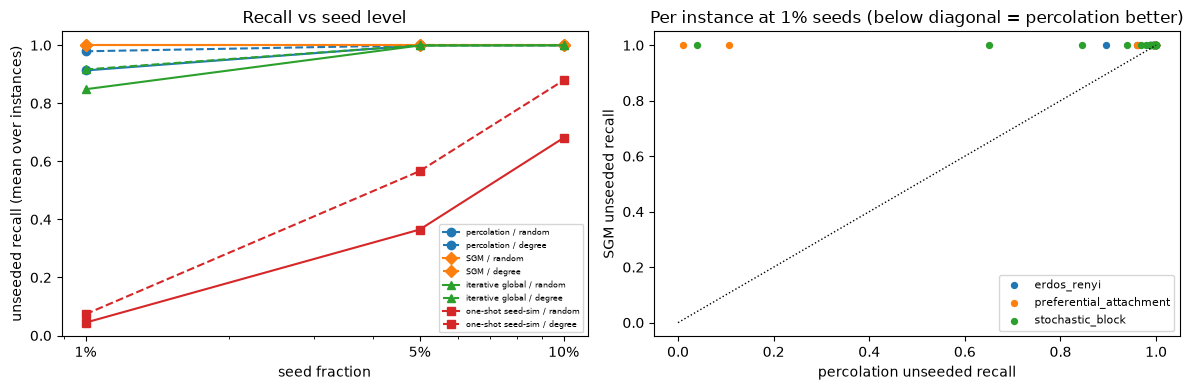

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (col, lab, c, mk) in (("perc", "percolation", "C0", "o"), ("sgm", "SGM", "C1", "D"), ("iter", "iterative global", "C2", "^"), ("sim", "one-shot seed-sim", "C3", "s")):
    for kind, ls in (("random", "-"), ("degree", "--")):
        g = cmp[cmp.seed_kind == kind].groupby("seed_pct")[f"unseeded_recall_{col}"].mean()
        ax[0].plot(g.index, g.values, ls, marker=mk, c=c, label=f"{lab} / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall (mean over instances)"); ax[0].legend(fontsize=6); ax[0].set_title("Recall vs seed level")
for fam, g in cmp[cmp.seed_pct == 1].groupby("family"):
    ax[1].scatter(g.unseeded_recall_perc, g.unseeded_recall_sgm, label=fam, s=18)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("percolation unseeded recall"); ax[1].set_ylabel("SGM unseeded recall")
ax[1].set_title("Per instance at 1% seeds (below diagonal = percolation better)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figs" / "comparison.png", dpi=130); plt.show()

## 6. Optimiser or objective? (Val)
If SGM's mapping has a **lower** edge-agreement than the ground-truth mapping, the optimiser got stuck in a local optimum; if it is **at least as high**, the objective itself cannot tell the right mapping apart (or an equally good wrong one exists).

In [11]:
rows = []
for pct in (1, 5):
    for name in list_instances("val"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, "random", pct)
        p_, inf_ = match_sgm(A_, B_, s_, **cfg4)
        f_found, f_true = edge_agreement(A_, B_, p_), edge_agreement(A_, B_, tr_)
        rows.append(dict(seeds=f"random {pct}%", instance=name, family=mt_["family"], f_found=f_found, f_truth=f_true,
                         found_vs_truth=f_found / f_true, unseeded_recall=evaluate(p_, tr_, s_, A_.shape[0])["unseeded_recall"],
                         iters=inf_.attrs["iters"]))
obj = pd.DataFrame(rows)
display(obj.round(3))
display(obj.groupby("seeds").apply(lambda g: pd.Series(dict(mean_recall=g.unseeded_recall.mean(), found_below_truth=(g.found_vs_truth < 0.999).mean(),
                                                           found_at_least_truth=(g.found_vs_truth >= 0.999).mean())), include_groups=False).round(3))

,seeds,instance,family,f_found,f_truth,found_vs_truth,unseeded_recall,iters
0,random 1%,erdos_renyi_easy_00,erdos_renyi,4988.0,4988.0,1.0,1.0,8
1,random 1%,erdos_renyi_hard_00,erdos_renyi,43788.0,43788.0,1.0,1.0,8
2,random 1%,erdos_renyi_medium_00,erdos_renyi,17998.0,17998.0,1.0,1.0,7
3,random 1%,preferential_attachment_easy_00,preferential_attachment,3298.0,3298.0,1.0,1.0,5
4,random 1%,preferential_attachment_hard_00,preferential_attachment,8768.0,8768.0,1.0,1.0,7
5,random 1%,preferential_attachment_medium_00,preferential_attachment,5952.0,5952.0,1.0,1.0,6
6,random 1%,stochastic_block_easy_00,stochastic_block,4840.0,4840.0,1.0,1.0,8
7,random 1%,stochastic_block_hard_00,stochastic_block,43986.0,43986.0,1.0,1.0,9
8,random 1%,stochastic_block_medium_00,stochastic_block,17990.0,17990.0,1.0,1.0,8
9,random 5%,erdos_renyi_easy_00,erdos_renyi,4988.0,4988.0,1.0,1.0,4


,mean_recall,found_below_truth,found_at_least_truth
seeds,,,
random 1%,1.0,0.0,1.0
random 5%,1.0,0.0,1.0


## 7. Confidence and rejection
The logged `score` of a match is its number of agreeing neighbour pairs under the final mapping. Filtering by `score >= tau` trades coverage for precision (Val, frozen config).

In [12]:
rows = []
for pct in (1, 5):
    for name in list_instances("val"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, "random", pct)
        _, inf_ = match_sgm(A_, B_, s_, **cfg4)
        inf_["correct"] = [tr_[a] == b for a, b in zip(inf_.node_a, inf_.node_b)]
        inf_["pct"] = pct
        rows.append(inf_)
cf = pd.concat(rows, ignore_index=True)
q = []
for pct, g in cf.groupby("pct"):
    for thr in (0, 2, 3, 5, 8):
        k = g[g.score >= thr]
        q.append(dict(seeds=f"random {pct}%", min_agreement=thr, kept=len(k) / len(g), precision_of_kept=k.correct.mean()))
display(pd.DataFrame(q).set_index(["seeds", "min_agreement"]).round(3))

kept  precision_of_kept
seeds     min_agreement                          
random 1% 0              1.000                1.0
          2              0.999                1.0
          3              0.997                1.0
          5              0.959                1.0
          8              0.804                1.0
random 5% 0              1.000                1.0
          2              0.999                1.0
          3              0.997                1.0
          5              0.958                1.0
          8              0.804                1.0

## Takeaways (SGM vs the other methods)

**SGM recovers every node in every run.** Unseeded recall is exactly 1.000 on all 216 Train+Val runs (36 instances x 2 seed strategies x 3 seed levels), including 1% seeds. Mean unseeded recall over Train+Val:

| seeds | SGM | percolation | iterative global | one-shot |
|---|---|---|---|---|
| 1% random | 1.000 | 0.913 | 0.848 | 0.044 |
| 1% degree | 1.000 | 0.979 | 0.916 | 0.073 |
| 5% (either) | 1.000 | 1.000 | 0.999 / 1.000 | 0.37 / 0.57 |
| 10% (either) | 1.000 | 1.000 | 1.000 | 0.68 / 0.88 |

Against percolation, SGM is better on 39% of instances at 1% seeds and equal on the rest; it is never worse. The gain comes entirely from the 1% regime, exactly where percolation sometimes fails to start (preferential attachment: 0.84 for percolation vs 1.000 for SGM).

**Why it works here.** Percolation can only grow from edges next to already matched pairs, so with 3 to 10 seeds it can stall. SGM scores a mapping by the agreement of *all* edges from the first iteration, so the unseeded nodes constrain each other without needing seed neighbours. In section 6 the edge agreement of SGM's mapping equals that of the ground-truth mapping on every Val instance at 1% and 5% seeds: the optimiser reaches the optimum of the objective, and that optimum is the true mapping.

**Cost and tuning.** It converges in 3 to 9 iterations on average (at most 20 over all runs; the cap of 30 was never hit). Runtime is about the same as my percolation implementation (0.57 s at n=1000) and slower than iterative global (0.21 s). The barycentre start was best on Train; the vote-based start and the 50/50 mix were not better, and a cap of 10 iterations is slightly too few (F1 0.97 to 0.99). Because the problem is non-convex, the start does matter in principle, but all three starts reached 0.97 or more.

**Confidence.** The agreement score of a match (neighbour pairs that agree under the final mapping) is a usable confidence: at `min_agreement=8` SGM still keeps 80% of nodes with precision 1.000 on Val, so a rejection threshold costs coverage without any precision benefit on these graphs.

**Caveats.**
- Results are at ceiling on Train/Val, so they cannot separate SGM from a perfect method; harder graphs (sparser, much noisier, or fewer seeds than 1%) would be needed to find its limits. I did not test those.
- The objective is non-convex and the method is a local search; it worked on all 54 graph pairs here, which does not guarantee it will on every unseen graph.
- It needs a dense n x n gradient (memory O(n^2)), same as my percolation implementation.
- The Test instances come from the same generator family, so I'd expect similar behaviour, but I cannot check Test accuracy.

**Conclusion.** On this evidence SGM is at least as good as percolation everywhere and strictly better at 1% seeds, at similar runtime. Percolation is still the submitted method; switching would be a decision for the main notebook, not for this throwaway comparison.